In [3]:
from IPython.display import Markdown, display
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import torch

from coolfrog.engine.cooldata import CoolData, CoolMetadata
from coolfrog.lib.config import HOST_CONFIG, DataConfig, Grid
from coolfrog.lib.datatypes import CHANNELS, Channel, NormalizationStats
from coolfrog.lib.experiment import PATH_EXPERIMENTS, markdown_table
from coolfrog.lib.plot import SOLID_COLOR

PATH_RESULTS = PATH_EXPERIMENTS / "01_min-max-normalization-stats-on-cooldata_partial" / "results"
global_range = pl.read_csv(PATH_RESULTS / "normalization_stats.csv")
metadata = CoolMetadata.load(HOST_CONFIG.n_splits, HOST_CONFIG.idx_split).designs
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

# 01 · Min-max normalization stats on CoolData

**Question:** can one global per-channel min and max over all 5692 CoolData designs map every channel to [-1, 1] for
Tadpole?

**Answer: no.**

1. The global extremes are physically implausible: velocities up to 400× the fastest inlet, heating up to 63× what the
   hottest body allows. Most likely some simulations diverged.
2. Min-max over such extremes squeezes a normal design into under 1 % of [-1, 1]: the model would see near-constant
   fields.
3. k and ε span 15 and 22 decades between the solver floor and their maxima, more than any linear scale resolves.

Source: [`experiments/01_min-max-normalization-stats-on-cooldata_partial`](../experiments/01_min-max-normalization-stats-on-cooldata_partial),
fluid voxels of every design at 1600x320x64.

## Result

Global fluid min and max per channel over all designs:

In [2]:
display(Markdown(markdown_table(global_range)))

| channel   | min       | max      |
|-----------|-----------|----------|
| Vx [m/s]  | -132      | 534      |
| Vy [m/s]  | -1.74e+03 | 1.26e+03 |
| Vz [m/s]  | -424      | 2.81e+03 |
| p [Pa]    | -4.39e+04 | 5.18e+07 |
| T [K]     | 139       | 4.07e+03 |
| k [m²/s²] | 1e-10     | 9.25e+04 |
| ε [m²/s³] | 1e-10     | 1.43e+12 |

## 1. The extremes are physically implausible

The design parameters bound what the flow can plausibly reach:

- **Velocity:** inlet speeds are 1 to 7 m/s. Bodies only deflect the flow, so no component should exceed a small
  multiple of 7 m/s.
- **Temperature:** air enters at 293.15 K and is heated by bodies of 20 to 80 °C. Without other heat sources it stays
  between 293.15 and 353.15 K, at most 60 K above the inlet.

| quantity     | global extreme | physical bound | extreme / bound |
|--------------|----------------|----------------|-----------------|
| \|Vx\| [m/s] | 534            | 7              | 76.2            |
| \|Vy\| [m/s] | 1.74e+03       | 7              | 249             |
| \|Vz\| [m/s] | 2.81e+03       | 7              | 402             |
| T − 293.15 K | 3.77e+03       | 60             | 62.9            |

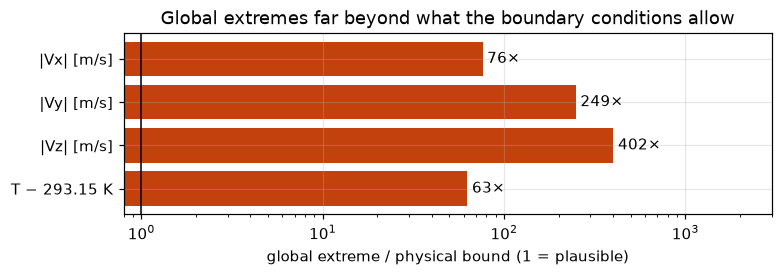

In [3]:
INLET_TEMPERATURE = 293.15
inlet_speed_max = metadata["V"].max()
body_temperature_max = metadata.select(pl.max_horizontal(f"T{body}" for body in range(1, 7))).max().item() + 273.15
extreme = {row["channel"]: max(abs(row["min"]), abs(row["max"])) for row in global_range.iter_rows(named=True)}
plausibility = pl.DataFrame(
    {
        "quantity": ["|Vx| [m/s]", "|Vy| [m/s]", "|Vz| [m/s]", "T − 293.15 K"],
        "global extreme": [
            *(extreme[channel.value] for channel in CHANNELS[:3]),
            extreme[Channel.TEMPERATURE.value] - INLET_TEMPERATURE,
        ],
        "physical bound": [inlet_speed_max] * 3 + [body_temperature_max - INLET_TEMPERATURE],
    }
).with_columns((pl.col("global extreme") / pl.col("physical bound")).alias("extreme / bound"))
display(Markdown(markdown_table(plausibility)))

figure, axis = plt.subplots(figsize=(7, 2.4), layout="constrained")
bars = axis.barh(plausibility["quantity"], plausibility["extreme / bound"], color="#c2410c")
axis.bar_label(bars, fmt="%.0f×", padding=3)
axis.axvline(1, color="black", linewidth=1)
axis.set_xscale("log")
axis.set_xlim(0.8, 3000)
axis.invert_yaxis()
axis.set_xlabel("global extreme / physical bound (1 = plausible)")
axis.set_title("Global extremes far beyond what the boundary conditions allow")
plt.show()

## 2. Min-max squeezes a normal design into a sliver of [-1, 1]

Design 3 is unremarkable: 5 m/s inlet, bodies at 39 to 79 °C. Normalized with the global min and max (left column),
every channel collapses to a single colour. The same slices on their own value range (right column) hold rich flow
structure: the information is there, min-max just hides it in a tiny part of the range.

Slices are top views at mid height, solids grey, shown at 400x80x16.

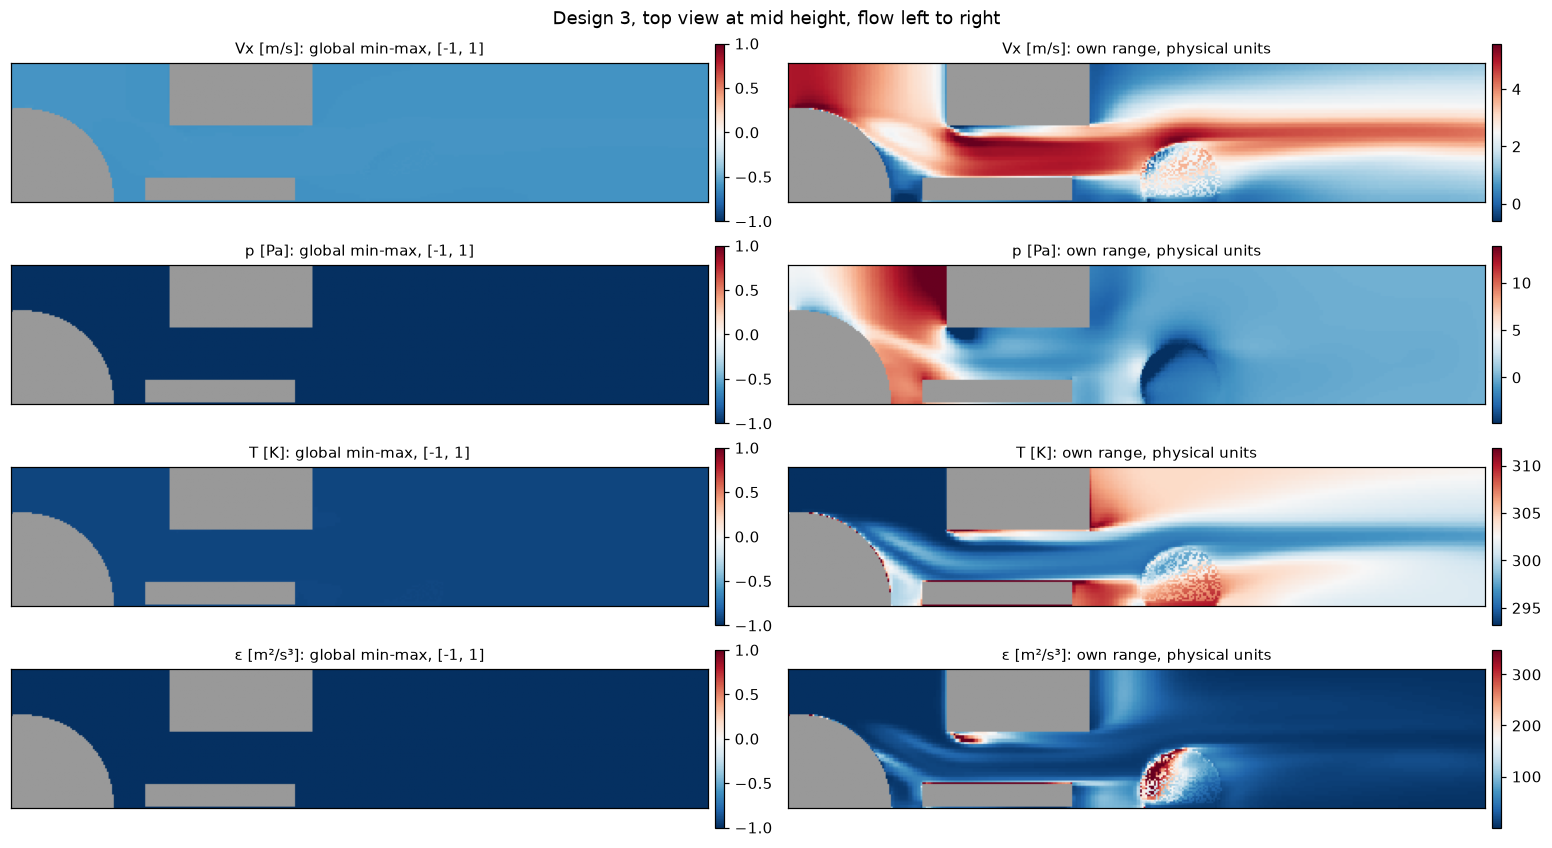

In [4]:
DESIGN = 3
SLICE_CHANNELS = (Channel.VX, Channel.PRESSURE, Channel.TEMPERATURE, Channel.TURBULENT_DISSIPATION_RATE)
GRID = Grid(latent_scale=1)

min_max = NormalizationStats(
    low=torch.tensor(global_range["min"].to_numpy(), dtype=torch.float32).view(-1, 1, 1, 1),
    high=torch.tensor(global_range["max"].to_numpy(), dtype=torch.float32).view(-1, 1, 1, 1),
    is_log=torch.zeros(len(CHANNELS), 1, 1, 1, dtype=torch.bool),
    batch_size=[],
)
design = CoolData(CoolMetadata(metadata.filter(pl.col("design_id") == DESIGN)), DataConfig(grid=GRID))[0]
physical, fluid = design.fields.numpy(), design.mask.numpy()
normalized = design.normalize(min_max).fields.numpy()
height = GRID.shape[2] // 2
extent_mm = (0.0, 1000 * GRID.extent[0], 0.0, 1000 * GRID.extent[1])
colormap = plt.colormaps["RdBu_r"].with_extremes(bad=SOLID_COLOR)

figure, axes = plt.subplots(len(SLICE_CHANNELS), 2, figsize=(14, 1.9 * len(SLICE_CHANNELS)), layout="constrained")
for row, channel in zip(axes, SLICE_CHANNELS, strict=True):
    index = CHANNELS.index(channel)
    for axis, volume, limits, title in (
        (row[0], normalized[index], (-1, 1), "global min-max, [-1, 1]"),
        (row[1], physical[index], tuple(np.quantile(physical[index][fluid], (0.01, 0.99))), "own range, physical units"),
    ):
        image = axis.imshow(
            np.where(fluid, volume, np.nan)[:, :, height].T,
            origin="lower",
            extent=extent_mm,
            cmap=colormap,
            vmin=limits[0],
            vmax=limits[1],
        )
        axis.set_title(f"{channel.value}: {title}", fontsize=10)
        axis.set_xticks([])
        axis.set_yticks([])
        axis.grid(False)
        figure.colorbar(image, ax=axis, fraction=0.025, pad=0.01)
figure.suptitle(f"Design {DESIGN}, top view at mid height, flow left to right")
plt.show()

Share of [-1, 1] that the central 98 % of design 3's fluid voxels (q0.01 to q0.99) occupy under global min-max:

In [5]:
low, high = np.quantile(physical[:, fluid].astype(np.float64), (0.01, 0.99), axis=1)
global_width = (global_range["max"] - global_range["min"]).to_numpy()
occupied = pl.DataFrame(
    {"channel": [channel.value for channel in CHANNELS], "share of [-1, 1] [%]": 100 * (high - low) / global_width}
)
display(Markdown(markdown_table(occupied)))

| channel   | share of [-1, 1] [%] |
|-----------|----------------------|
| Vx [m/s]  | 0.931                |
| Vy [m/s]  | 0.121                |
| Vz [m/s]  | 0.0517               |
| p [Pa]    | 3.62e-05             |
| T [K]     | 0.477                |
| k [m²/s²] | 0.00136              |
| ε [m²/s³] | 2.43e-08             |

## 3. k and ε need a log scale

k and ε are floored at 1e-10 by the solver and reach 9.3e4 and 1.4e12: 15 and 22 decades. Within design 3 alone they
spread over 4 to 6 decades (below), so a linear scale resolves only the largest values and maps everything else onto
the same normalized value.

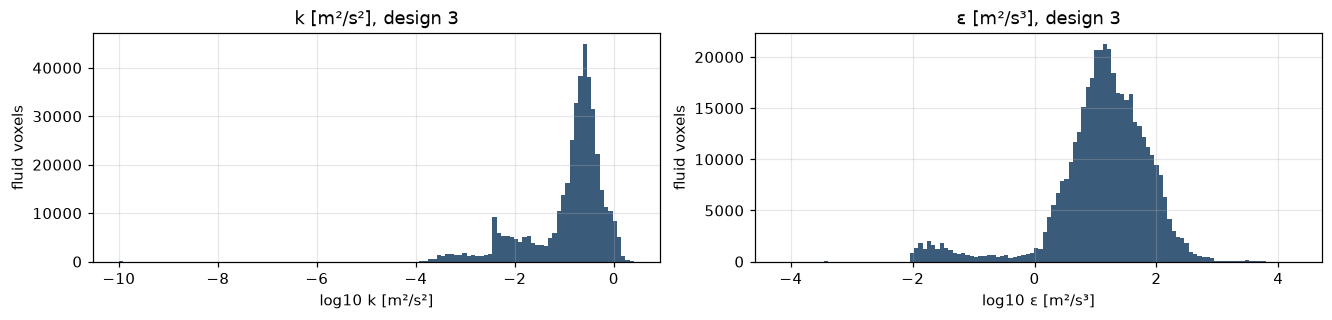

In [6]:
figure, axes = plt.subplots(1, 2, figsize=(12, 2.8), layout="constrained")
for axis, channel in zip(axes, (Channel.TURBULENT_KINETIC_ENERGY, Channel.TURBULENT_DISSIPATION_RATE), strict=True):
    values = physical[CHANNELS.index(channel)][fluid]
    axis.hist(np.log10(np.maximum(values, 1e-10)), bins=120, color="#3b5b7a")
    axis.set_xlabel(f"log10 {channel.value}")
    axis.set_ylabel("fluid voxels")
    axis.set_title(f"{channel.value}, design {DESIGN}")
plt.show()

## Conclusion

- Global min-max is unusable as long as the implausible extremes stay in the data.
- Next step, experiment 02: measure the full value distribution (histograms, quantiles, per-design stats) to find the
  designs behind the extremes and pick an outlier-robust normalization, with a log scale for k and ε.